In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("jehanbhathena/weather-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'weather-dataset' dataset.
Path to dataset files: /kaggle/input/weather-dataset


In [ ]:
import os
from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split

from torchvision import datasets, transforms

# =========================================================
# CONFIG
# =========================================================

DATASET_PATH = path + '/dataset'
# Example Kaggle path:
# /kaggle/input/weather-dataset/dataset

BATCH_SIZE = 32
IMAGE_SIZE = 128
EPOCHS = 6
LEARNING_RATE = 1e-3

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", DEVICE)

Using device: cuda


In [ ]:
# =========================================================
# TRANSFORMS
# =========================================================

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# =========================================================
# DATASET
# =========================================================

dataset = datasets.ImageFolder(
    root=DATASET_PATH,
    transform=transform
)

class_names = dataset.classes
num_classes = len(class_names)

print("Classes:", class_names)

# Train / Validation split
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size]
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)



Classes: ['dew', 'fogsmog', 'frost', 'glaze', 'hail', 'lightning', 'rain', 'rainbow', 'rime', 'sandstorm', 'snow']


In [ ]:
print("Dataset size:", len(dataset))
print("Classes:", dataset.classes)
print("Class to idx:", dataset.class_to_idx)

import os
print(os.listdir(DATASET_PATH))

Dataset size: 6862
Classes: ['dew', 'fogsmog', 'frost', 'glaze', 'hail', 'lightning', 'rain', 'rainbow', 'rime', 'sandstorm', 'snow']
Class to idx: {'dew': 0, 'fogsmog': 1, 'frost': 2, 'glaze': 3, 'hail': 4, 'lightning': 5, 'rain': 6, 'rainbow': 7, 'rime': 8, 'sandstorm': 9, 'snow': 10}
['hail', 'rainbow', 'frost', 'rime', 'fogsmog', 'snow', 'rain', 'glaze', 'lightning', 'sandstorm', 'dew']


# CNN

In [ ]:
# =========================================================
# SIMPLE CNN
# =========================================================

class WeatherCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),

            nn.Linear(128 * (IMAGE_SIZE // 8) * (IMAGE_SIZE // 8), 256),
            nn.ReLU(),
            nn.Dropout(0.5),

            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = WeatherCNN(num_classes).to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)


In [ ]:
# =========================================================
# TRAINING
# =========================================================

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

for epoch in range(EPOCHS):

    # ---------------- TRAIN ----------------
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()

    train_acc = 100 * train_correct / train_total
    avg_train_loss = train_loss / len(train_loader)

    # ---------------- VALIDATION ----------------
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_acc = 100 * val_correct / val_total
    avg_val_loss = val_loss / len(val_loader)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss/len(train_loader):.4f} "
        f"Train Acc: {train_acc:.2f}% "
        f"Val Loss: {val_loss/len(val_loader):.4f} "
        f"Val Acc: {val_acc:.2f}%"
    )

    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)


# =========================================================
# SAVE MODEL
# =========================================================

# torch.save(model.state_dict(), "weather_cnn.pth")
checkpoint = {
    "epoch": EPOCHS,

    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),

    "train_losses": train_losses,
    "val_losses": val_losses,

    "train_accuracies": train_accuracies,
    "val_accuracies": val_accuracies,

    "class_names": class_names
}

torch.save(checkpoint, "weather_cnn_checkpoint.pth")

print("Checkpoint saved.")

# print("Model saved as weather_cnn.pth")

Epoch [1/6] Train Loss: 1.4555 Train Acc: 53.32% Val Loss: 1.0488 Val Acc: 67.59%
Epoch [2/6] Train Loss: 1.1047 Train Acc: 63.31% Val Loss: 1.0938 Val Acc: 63.22%
Epoch [3/6] Train Loss: 0.9348 Train Acc: 68.76% Val Loss: 0.8443 Val Acc: 71.16%
Epoch [4/6] Train Loss: 0.8387 Train Acc: 72.49% Val Loss: 0.8295 Val Acc: 70.14%
Epoch [5/6] Train Loss: 0.6733 Train Acc: 77.43% Val Loss: 0.8075 Val Acc: 73.49%
Epoch [6/6] Train Loss: 0.5196 Train Acc: 82.42% Val Loss: 0.8102 Val Acc: 73.71%
Checkpoint saved.


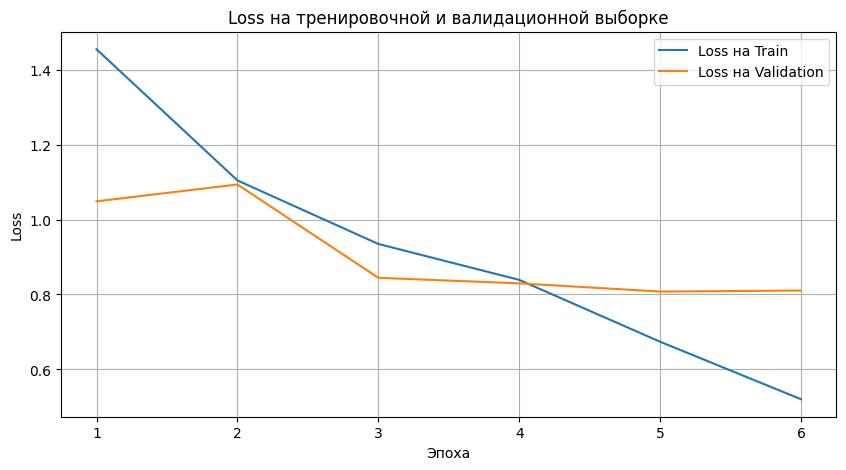

In [ ]:
import matplotlib.pyplot as plt

epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(10, 5))

plt.plot(epochs_range, train_losses, label="Loss на Train")
plt.plot(epochs_range, val_losses, label="Loss на Validation")

plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.title("Loss на тренировочной и валидационной выборке")

plt.legend()

plt.grid(True)

plt.show()

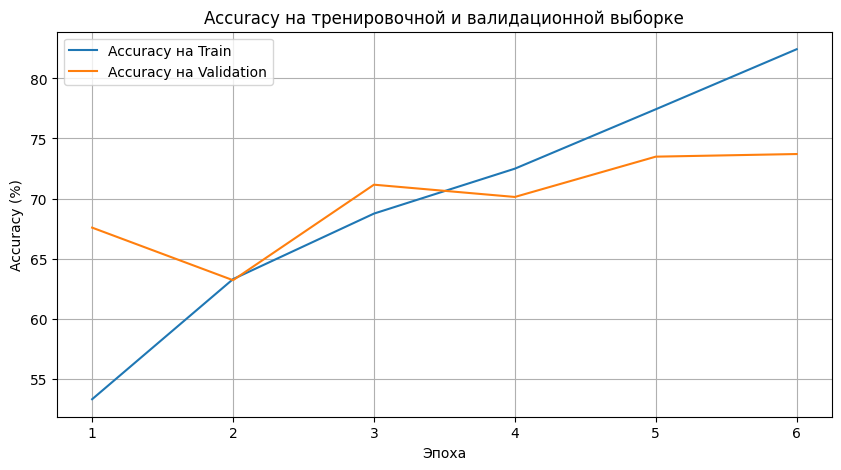

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(epochs_range, train_accuracies, label="Accuracy на Train")
plt.plot(epochs_range, val_accuracies, label="Accuracy на Validation")

plt.xlabel("Эпоха")
plt.ylabel("Accuracy (%)")
plt.title("Accuracy на тренировочной и валидационной выборке")

plt.legend()

plt.grid(True)

plt.show()

{'dew': {'precision': 0.8120300751879699, 'recall': 0.8120300751879699, 'f1-score': 0.8120300751879699, 'support': 133.0}, 'fogsmog': {'precision': 0.7637130801687764, 'recall': 0.905, 'f1-score': 0.8283752860411899, 'support': 200.0}, 'frost': {'precision': 0.57, 'recall': 0.6063829787234043, 'f1-score': 0.5876288659793815, 'support': 94.0}, 'glaze': {'precision': 0.6173913043478261, 'recall': 0.6228070175438597, 'f1-score': 0.6200873362445415, 'support': 114.0}, 'hail': {'precision': 0.7377049180327869, 'recall': 0.7258064516129032, 'f1-score': 0.7317073170731707, 'support': 124.0}, 'lightning': {'precision': 0.7906976744186046, 'recall': 0.8717948717948718, 'f1-score': 0.8292682926829268, 'support': 78.0}, 'rain': {'precision': 0.6792452830188679, 'recall': 0.6792452830188679, 'f1-score': 0.6792452830188679, 'support': 106.0}, 'rainbow': {'precision': 0.75, 'recall': 0.5892857142857143, 'f1-score': 0.66, 'support': 56.0}, 'rime': {'precision': 0.896969696969697, 'recall': 0.69483568

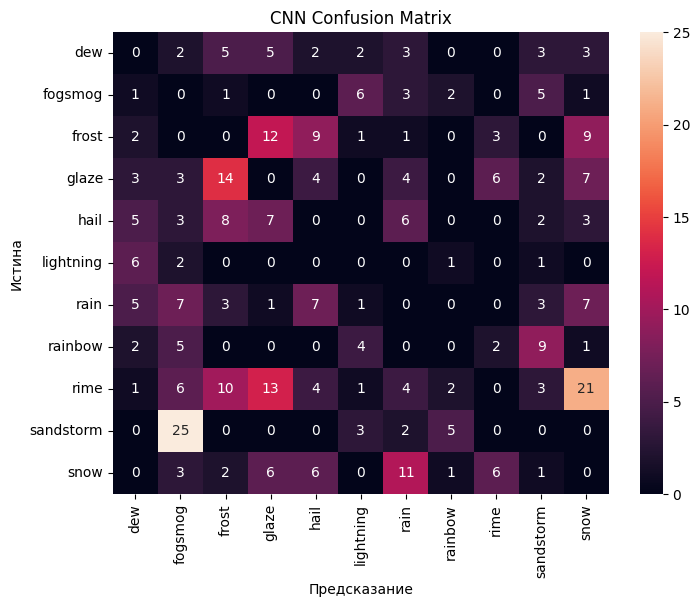

In [ ]:
import seaborn as sns
import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

all_preds = []
all_labels = []

model.eval()

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(DEVICE)

        outputs = model(images)

        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

cnn_report = classification_report(
    all_labels,
    all_preds,
    target_names=class_names,
    output_dict=True
)
print(cnn_report)

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8, 6))

sns.heatmap(
    (cm - np.eye(N=num_classes) * np.diag(cm)).astype(int),
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Предсказание")
plt.ylabel("Истина")
plt.title("CNN Confusion Matrix")

plt.show()

# Random forest

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from tqdm import tqdm

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
from sklearn.model_selection import train_test_split

from joblib import dump


# =========================================================
# CONFIG
# =========================================================

DATASET_PATH = "/kaggle/input/weather-dataset/dataset"

IMAGE_SIZE = 64
# Smaller image size recommended for Random Forest

N_ESTIMATORS = 200
RANDOM_STATE = 42


# =========================================================
# LOAD DATA
# =========================================================

X = []
y = []

class_names = sorted(os.listdir(DATASET_PATH))

print("Classes:", class_names)

for class_idx, class_name in enumerate(class_names):

    class_path = os.path.join(DATASET_PATH, class_name)

    for image_name in tqdm(
        os.listdir(class_path),
        desc=f"Loading {class_name}"
    ):

        image_path = os.path.join(class_path, image_name)

        try:
            # Load image
            image = Image.open(image_path).convert("RGB")

            # Resize
            image = image.resize((IMAGE_SIZE, IMAGE_SIZE))

            # Convert to numpy
            image = np.array(image)

            # Flatten image:
            # (64,64,3) -> (12288,)
            image = image.flatten()

            X.append(image)
            y.append(class_idx)

        except Exception as e:
            print(f"Failed to load {image_path}: {e}")

X = np.array(X)
y = np.array(y)

print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)


# =========================================================
# TRAIN / VALIDATION SPLIT
# =========================================================

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train size:", len(X_train))
print("Validation size:", len(X_val))


# =========================================================
# RANDOM FOREST
# =========================================================

rf = RandomForestClassifier(
    n_estimators=N_ESTIMATORS,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=1
)

print("Training Random Forest...")

rf.fit(X_train, y_train)

print("Training complete.")
# =========================================================
# SAVE MODEL
# =========================================================

dump(rf, "weather_random_forest.joblib")

print("Model saved as weather_random_forest.joblib")

[Parallel(n_jobs=2)]: Using backend ThreadingBackend with 2 concurrent workers.
[Parallel(n_jobs=2)]: Done  46 tasks      | elapsed:    0.1s
[Parallel(n_jobs=2)]: Done 196 tasks      | elapsed:    0.2s
[Parallel(n_jobs=2)]: Done 200 out of 200 | elapsed:    0.2s finished



Validation Accuracy: 0.6504

Classification Report:

{'dew': {'precision': 0.7114093959731543, 'recall': 0.7571428571428571, 'f1-score': 0.7335640138408305, 'support': 140.0}, 'fogsmog': {'precision': 0.65625, 'recall': 0.8647058823529412, 'f1-score': 0.7461928934010152, 'support': 170.0}, 'frost': {'precision': 0.46774193548387094, 'recall': 0.30526315789473685, 'f1-score': 0.36942675159235666, 'support': 95.0}, 'glaze': {'precision': 0.6373626373626373, 'recall': 0.453125, 'f1-score': 0.5296803652968036, 'support': 128.0}, 'hail': {'precision': 0.5692307692307692, 'recall': 0.6271186440677966, 'f1-score': 0.5967741935483871, 'support': 118.0}, 'lightning': {'precision': 0.6835443037974683, 'recall': 0.7105263157894737, 'f1-score': 0.6967741935483871, 'support': 76.0}, 'rain': {'precision': 0.6933333333333334, 'recall': 0.49523809523809526, 'f1-score': 0.5777777777777777, 'support': 105.0}, 'rainbow': {'precision': 0.7272727272727273, 'recall': 0.17391304347826086, 'f1-score': 0.2807

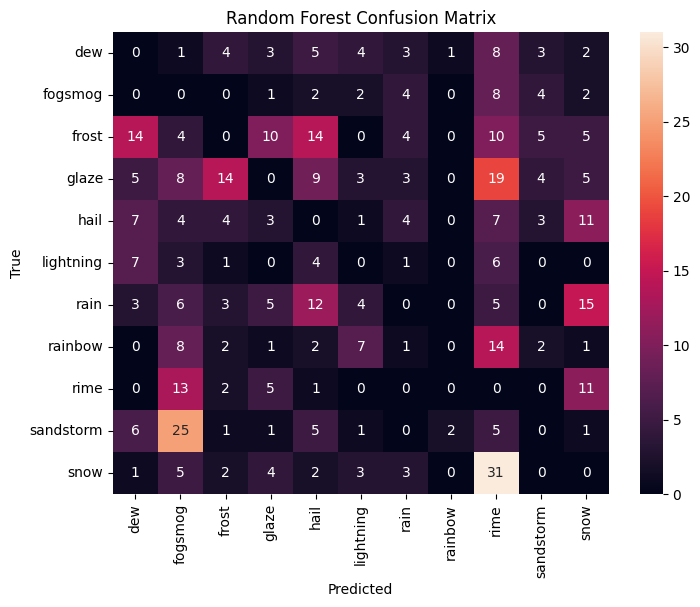

In [ ]:
# =========================================================
# PREDICTION
# =========================================================

y_pred = rf.predict(X_val)


# =========================================================
# METRICS
# =========================================================

accuracy = accuracy_score(y_val, y_pred)

print(f"\nValidation Accuracy: {accuracy:.4f}\n")

print("Classification Report:\n")


rf_report = classification_report(
        y_val,
        y_pred,
        target_names=class_names,
        output_dict=True
    )
print(rf_report)


# =========================================================
# CONFUSION MATRIX
# =========================================================

cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    (cm - np.eye(N=num_classes) * np.diag(cm)).astype(int),
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Random Forest Confusion Matrix")

plt.show()

# SVM

Classes: ['dew', 'fogsmog', 'frost', 'glaze', 'hail', 'lightning', 'rain', 'rainbow', 'rime', 'sandstorm', 'snow']


Loading snow: 100%|██████████| 621/621 [00:05<00:00, 116.42it/s]


Dataset shape: (6862, 12288)
Labels shape: (6862,)
Train size: 5489
Validation size: 1373
Scaling features...
Scaling complete.
Training SVM...
[LibSVM]Training complete.

Validation Accuracy: 0.6679

Classification Report:

              precision    recall  f1-score   support

         dew       0.87      0.76      0.81       140
     fogsmog       0.66      0.89      0.76       170
       frost       0.52      0.40      0.45        95
       glaze       0.59      0.52      0.55       128
        hail       0.57      0.60      0.59       118
   lightning       0.77      0.76      0.77        76
        rain       0.56      0.49      0.52       105
     rainbow       0.60      0.46      0.52        46
        rime       0.72      0.78      0.75       232
   sandstorm       0.86      0.73      0.79       139
        snow       0.51      0.59      0.55       124

    accuracy                           0.67      1373
   macro avg       0.66      0.63      0.64      1373
weighted avg     

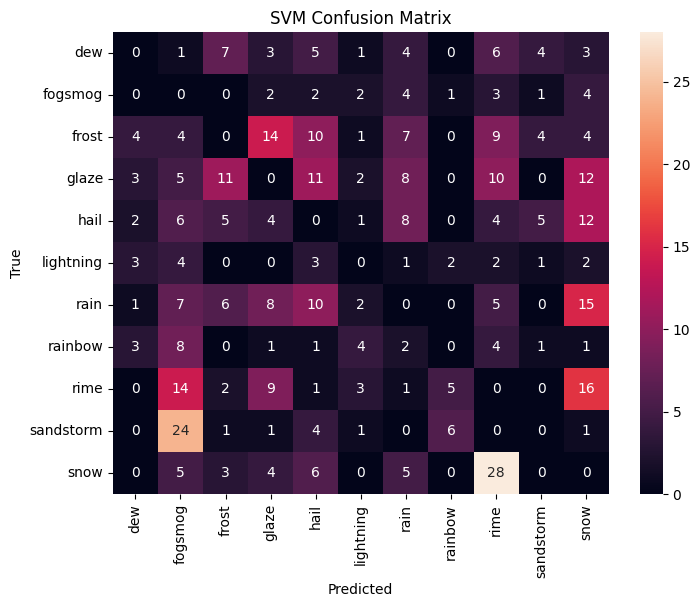

Results saved to svm_results.json
Model saved as weather_svm.joblib


In [ ]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from tqdm import tqdm

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from joblib import dump


# =========================================================
# CONFIG
# =========================================================

DATASET_PATH = "/kaggle/input/weather-dataset/dataset"

IMAGE_SIZE = 64

RANDOM_STATE = 42

# SVM parameters
KERNEL = "rbf"
C = 10
GAMMA = "scale"


# =========================================================
# LOAD DATA
# =========================================================

X = []
y = []

class_names = sorted(os.listdir(DATASET_PATH))

print("Classes:", class_names)

for class_idx, class_name in enumerate(class_names):

    class_path = os.path.join(DATASET_PATH, class_name)

    for image_name in tqdm(
        os.listdir(class_path),
        desc=f"Loading {class_name}"
    ):

        image_path = os.path.join(class_path, image_name)

        try:
            # Load image
            image = Image.open(image_path).convert("RGB")

            # Resize
            image = image.resize((IMAGE_SIZE, IMAGE_SIZE))

            # Convert to numpy
            image = np.array(image)

            # Flatten:
            # (64,64,3) -> (12288,)
            image = image.flatten()

            X.append(image)
            y.append(class_idx)

        except Exception as e:
            print(f"Failed to load {image_path}: {e}")

X = np.array(X)
y = np.array(y)

print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)


# =========================================================
# TRAIN / VALIDATION SPLIT
# =========================================================

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train size:", len(X_train))
print("Validation size:", len(X_val))


# =========================================================
# FEATURE NORMALIZATION
# =========================================================

print("Scaling features...")

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_val = scaler.transform(X_val)

print("Scaling complete.")


# =========================================================
# SVM
# =========================================================

svm = SVC(
    kernel=KERNEL,
    C=C,
    gamma=GAMMA,
    probability=True,
    verbose=True
)

print("Training SVM...")

svm.fit(X_train, y_train)

print("Training complete.")


# =========================================================
# PREDICTION
# =========================================================

y_pred = svm.predict(X_val)


# =========================================================
# METRICS
# =========================================================

accuracy = accuracy_score(y_val, y_pred)

print(f"\nValidation Accuracy: {accuracy:.4f}\n")

svm_report = classification_report(
    y_val,
    y_pred,
    target_names=class_names,
    output_dict=True
)

print("Classification Report:\n")

print(svm_report)


# =========================================================
# CONFUSION MATRIX
# =========================================================

cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    (cm - np.eye(N=num_classes) * np.diag(cm)).astype(int),
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("SVM Confusion Matrix")

plt.show()


# =========================================================
# SAVE RESULTS
# =========================================================

results = {
    "accuracy": accuracy,
    "classification_report": report,
    "confusion_matrix": cm.tolist(),
    "class_names": class_names
}

with open("svm_results.json", "w") as f:
    json.dump(results, f, indent=4)

print("Results saved to svm_results.json")


# =========================================================
# SAVE MODEL
# =========================================================

model_data = {
    "model": svm,
    "scaler": scaler,
    "class_names": class_names,
    "image_size": IMAGE_SIZE
}

dump(model_data, "weather_svm.joblib")

print("Model saved as weather_svm.joblib")

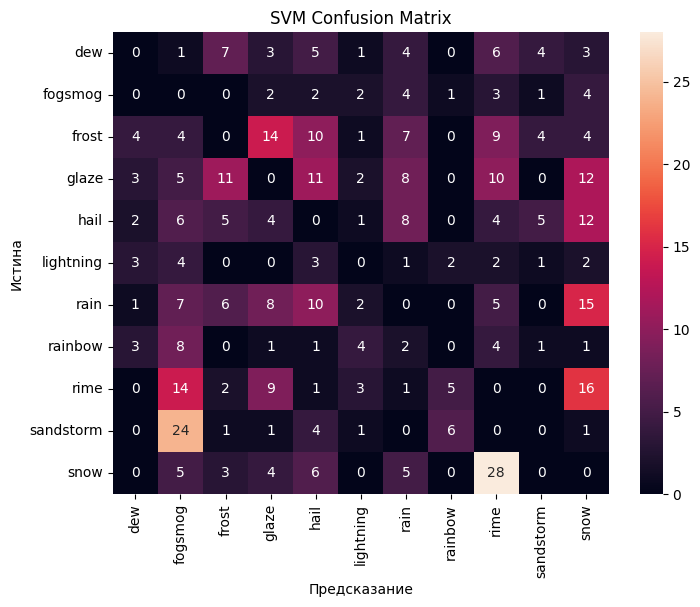

In [ ]:
# =========================================================
# CONFUSION MATRIX
# =========================================================

cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    (cm - np.eye(N=num_classes) * np.diag(cm)).astype(int),
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Предсказание")
plt.ylabel("Истина")
plt.title("SVM Confusion Matrix")

plt.show()

In [ ]:
svm_report = classification_report(
        y_val,
        y_pred,
        target_names=class_names,
        output_dict=True
)

In [ ]:
metrics = ["precision", "recall", "f1-score"]

cnn_scores = {
    metric: [cnn_report[c][metric] for c in class_names]
    for metric in metrics
}

rf_scores = {
    metric: [rf_report[c][metric] for c in class_names]
    for metric in metrics
}

svm_scores = {
    metric: [svm_report[c][metric] for c in class_names]
    for metric in metrics
}

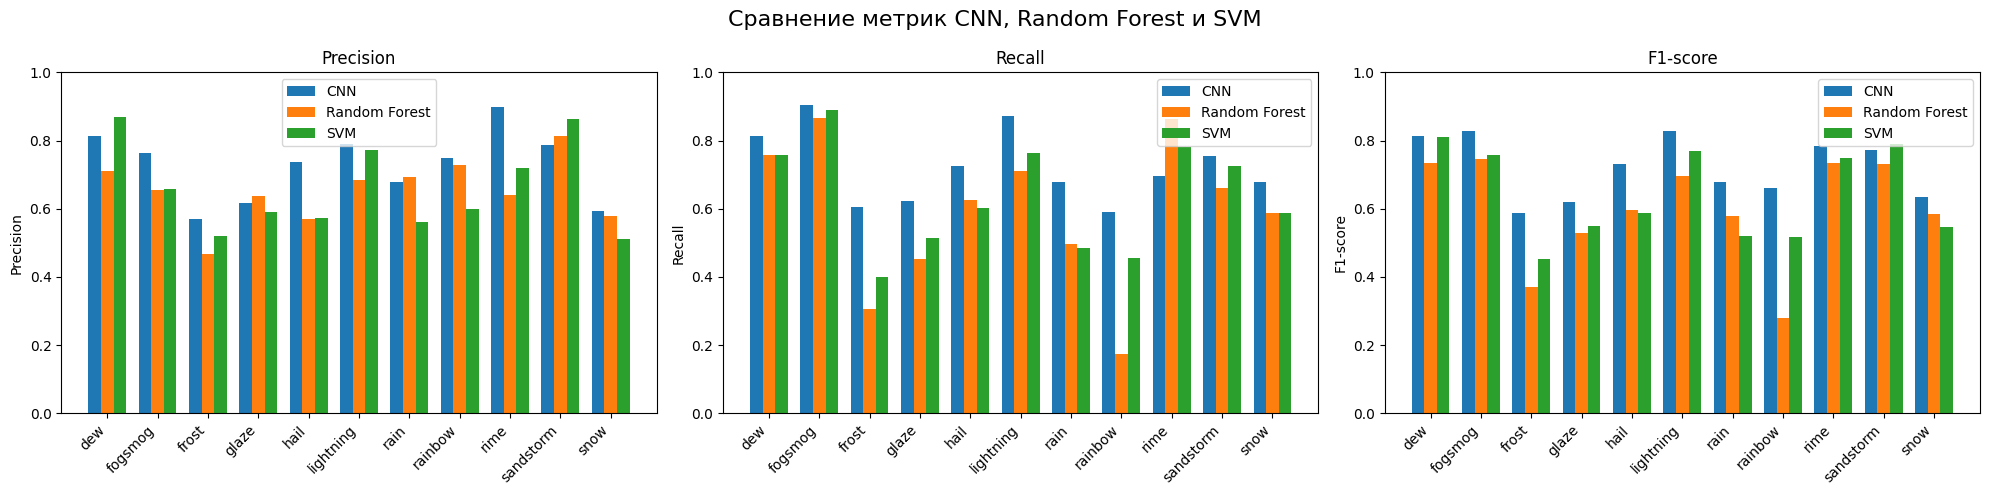

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

metrics = ["precision", "recall", "f1-score"]

x = np.arange(len(class_names))

width = 0.25

fig, axes = plt.subplots(
    1,
    3,
    figsize=(20, 5)
)

for idx, metric in enumerate(metrics):

    ax = axes[idx]

    ax.bar(
        x - width,
        cnn_scores[metric],
        width,
        label="CNN"
    )

    ax.bar(
        x,
        rf_scores[metric],
        width,
        label="Random Forest"
    )

    ax.bar(
        x + width,
        svm_scores[metric],
        width,
        label="SVM"
    )

    ax.set_title(metric.capitalize())

    ax.set_xticks(x)

    ax.set_xticklabels(
      class_names,
      rotation=45,
      ha="right"
    )

    ax.set_ylim(0, 1)

    ax.set_ylabel(metric.capitalize())

    ax.legend()

plt.suptitle(
    "Сравнение метрик CNN, Random Forest и SVM",
    fontsize=16
)

plt.tight_layout()

plt.show()

In [ ]:
CNN